![Banner](../images/08_bayesian_kriging.png)

# Bayesian Kriging in One Call (`bayesian_kriging`)

**Dataset:** Jura soil survey (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples of seven heavy metals; `jura_grid.csv` for maps)

**Target:** log-transformed metal concentrations (mg/kg), cadmium in detail

**Library:** `geolattice.geostatistics.bayesian_kriging` and `correlation_function` (module `geolattice.geostatistics.kriging.bayesian_kriging`)

**Before this notebook:** [Bayesian kriging](05_08_02_bayesian_kriging.ipynb), which explains the model behind the function in depth.

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [What the function computes](#what-the-function-computes)
    - 2.2 [Correlation models and the meaning of "range"](#correlation-models-and-the-meaning-of-range)
    - 2.3 [The predictive table](#the-predictive-table)
    - 2.4 [Signal or observation](#signal-or-observation)
    - 2.5 [Defaults and cost](#defaults-and-cost)
3. [Python Setup](#python-setup)
4. [Correlation Models with `correlation_function`](#correlation-models-with-correlation_function)
5. [The Basic Call](#the-basic-call)
6. [Options](#options)
    - 6.1 [Quantiles](#quantiles)
    - 6.2 [Correlation model and grids](#correlation-model-and-grids)
    - 6.3 [Priors](#priors)
    - 6.4 [Trend and covariates](#trend-and-covariates)
    - 6.5 [Signal or observation](#signal-or-observation-1)
    - 6.6 [Getting the fitted model back](#getting-the-fitted-model-back)
7. [Validation in a Few Lines](#validation-in-a-few-lines)
8. [Many Variables in a Loop](#many-variables-in-a-loop)
9. [Back to Original Units](#back-to-original-units)
10. [A Map in One Call](#a-map-in-one-call)
11. [Run Time](#run-time)
12. [Summary and Conclusions](#summary-and-conclusions)
    - 12.1 [Cheat sheet](#cheat-sheet)
13. [References](#references)

***
## Overview

`bayesian_kriging` is the one-call interface to [`BayesianKriging`](05_08_02_bayesian_kriging.ipynb). It fits the model and returns a table of predictions:

```python
from geolattice.geostatistics import bayesian_kriging

table = bayesian_kriging(coords, values, coords_pred, model="exponential")
#        mean      sd     q05     q50     q95
```

* The **posterior predictive mean** and **standard deviation** at each prediction point.
* **Quantiles** of the full predictive distribution.
* Behind the call, a full Bayesian analysis: the range and relative nugget are averaged over a grid weighted by their posterior, and the trend and variance are integrated out exactly.

| Argument | Meaning | Default |
|---|---|---|
| `coords`, `values`, `coords_pred` | training locations (n, 2), values (n,), prediction locations (m, 2) | n/a |
| `model` | correlation model: `exponential`, `spherical`, `gaussian`, `matern`, `cubic`, `stable` | `"exponential"` |
| `trend` | polynomial trend degree in the coordinates (0, 1, 2) | 0 |
| `quantiles` | predictive quantiles to report | (0.05, 0.5, 0.95) |
| `covariates`, `covariates_pred` | covariates at the data and at the prediction points | None |
| `signal` | predict the noise-free signal (True) or a new observation (False) | True |
| `return_model` | also return the fitted `BayesianKriging` | False |
| `**kwargs` | `range_grid`, `nugget_grid`, `range_prior`, `nugget_prior`, `beta_prior`, `sigma2_prior`, `nu` | n/a |

The notebook:

* explains what the call computes and how to read the table;
* plots the correlation models with `correlation_function`;
* goes through every option on the Jura cadmium data;
* uses the function for validation, and in a loop over all seven Jura metals;
* back-transforms log-scale quantiles to mg/kg;
* draws a map with a single call, and times the function.

***
## Theory

### What the function computes

The model is Gaussian with an unknown trend, variance, range and relative nugget:

$$
\mathbf{z} \sim \mathcal{N}\bigl(\mathbf{F}\boldsymbol\beta,\; \sigma^2[\mathbf{R}(\phi) + \tau\mathbf{I}]\bigr).
$$

`bayesian_kriging` performs three steps.

1. **Grid posterior.** For every $(\phi_k, \tau_k)$ on `range_grid` × `nugget_grid`, the trend $\boldsymbol\beta$ and variance $\sigma^2$ are integrated out under the conjugate prior. The marginal likelihood $p(\mathbf{z} \mid \phi_k, \tau_k)$ and a Student-t predictive $t_{\nu_k}(\mu_k(\mathbf{x}_0), s_k^2(\mathbf{x}_0))$ then follow in closed form, and the posterior weights are
$$
w_k \propto p(\phi_k)\,p(\tau_k)\,p(\mathbf{z} \mid \phi_k, \tau_k).
$$
2. **Predictive mixture.** At each prediction point,
$$
p\bigl(z(\mathbf{x}_0) \mid \mathbf{z}\bigr) = \sum_k w_k\, t_{\nu_k}\bigl(\mu_k(\mathbf{x}_0), s_k^2(\mathbf{x}_0)\bigr).
$$
3. **Summary table:**
    * mean $\sum_k w_k\mu_k$;
    * sd from $\operatorname{Var} = \sum_k w_k\bigl[s_k^2\nu_k/(\nu_k - 2) + \mu_k^2\bigr] - \text{mean}^2$;
    * each quantile $q_p$ solving $\sum_k w_k\, T_{\nu_k}\bigl((q_p - \mu_k)/s_k\bigr) = p$, found by bisection.

All three are exact: no sampling is involved.

### Correlation models and the meaning of "range"

`correlation_function(h, model, range_, nu)` returns $\rho(h) = 1 - \gamma(h)$ for a unit-sill variogram, with the same parametrization as `Variogram`. The "range" parameter $a$ means different things for different models:

| Model | $\rho(h)$ | Distance where $\rho$ falls to about 0.05 |
|---|---|---|
| spherical | $1 - \tfrac32\tfrac{h}{a} + \tfrac12\bigl(\tfrac{h}{a}\bigr)^3$ for $h < a$, else 0 | $0.81\,a$ (exactly 0 at $a$) |
| exponential | $e^{-h/a}$ | $3a$ |
| gaussian | $e^{-(h/a)^2}$ | $\sqrt{3}\,a$ |
| matern | $\frac{2^{1-\nu}}{\Gamma(\nu)}(h/a)^\nu K_\nu(h/a)$ | depends on $\nu$ |

Grids of ranges should be chosen with that in mind. The default `range_grid` is 30 values log-spaced from 2% to 100% of the largest inter-point distance.

### The predictive table

* `mean` and `sd` are the mean and standard deviation of the predictive mixture.
* `qNN` is the $NN$% quantile. With many data the mixture is close to a Gaussian, and $q_{05}$-$q_{95}$ spans about mean ± 1.645 sd. With few data, or a posterior spread over very different ranges, its tails are heavier and the quantiles spread farther.
* The table is in the units of `values`. For log-transformed data, the quantiles back-transform exactly ($\exp q_p$ is the $p$ quantile of the original variable) but the mean does not (Section 9).

### Signal or observation

With a nugget $\tau > 0$:

* `signal=True` predicts the noise-free process $\mathbf{f}^\top\boldsymbol\beta + S(\mathbf{x})$;
* `signal=False` predicts a **new measurement**, adding the nugget variance $\sigma^2\tau$.

Maps of the underlying field use the signal; comparisons with held-out measurements must use observations, otherwise the intervals look too narrow.

### Defaults and cost

* **Defaults.**
    * Grids: the range grid of Section 2.2, and the relative nugget on $\{0, 0.1, 0.25, 0.5, 1\}$.
    * Priors: uniform on both grids, flat on the trend, $1/\sigma^2$ on the variance.
* **Cost.**
    * Fitting needs one Cholesky factorization of an $n \times n$ matrix per grid point, $O(G\,n^3)$ for $G$ grid points.
    * Prediction costs $O(G\,m\,n^2)$ for $m$ points.
    * Quantiles add a bisection over the mixture cdf.

***
## Python Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import BayesianKriging, bayesian_kriging, correlation_function

print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")


DATA = "../../../../Data/00_shared/data_geostatistics/"
jura = pd.read_csv(DATA + "jura_data.csv", index_col=0)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr, te = next(sss.split(jura, jura["Landuse"]))
train, test = jura.iloc[tr].reset_index(drop=True), jura.iloc[te].reset_index(drop=True)
xy, xy_test = train[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
z, z_test = np.log(train["Cd"].to_numpy(float)), np.log(test["Cd"].to_numpy(float))
print(f"training {len(train)}, test {len(test)}; target log(Cd)")

pygstat version: 0.3.49
training 251, test 108; target log(Cd)


***
## Correlation Models with `correlation_function`

The correlation of each model with the parameter `range_ = 1`, and the Matérn family for three smoothness values `nu`. The dotted line at 0.05 marks the "practical range".

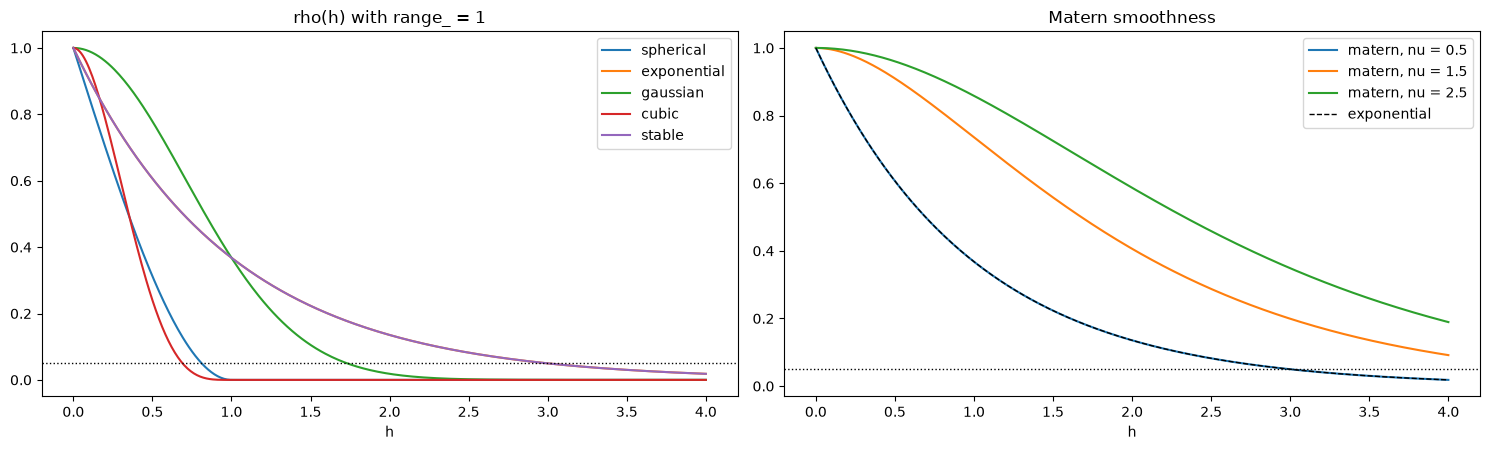

distance where rho drops below 0.05 (range_ = 1): {'spherical': 0.81, 'exponential': 3.0, 'gaussian': 1.73}
✅ [PASS] matern with nu = 0.5 equals exponential  


In [2]:
h = np.linspace(0, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for model in ["spherical", "exponential", "gaussian", "cubic", "stable"]:
    axes[0].plot(h, correlation_function(h, model, 1.0), label=model)
axes[0].axhline(0.05, color="k", ls=":", lw=1)
axes[0].set_title("rho(h) with range_ = 1")
axes[0].set_xlabel("h")
axes[0].legend()
for nu in [0.5, 1.5, 2.5]:
    axes[1].plot(h, correlation_function(h, "matern", 1.0, nu=nu), label=f"matern, nu = {nu}")
axes[1].plot(h, correlation_function(h, "exponential", 1.0), "k--", lw=1, label="exponential")
axes[1].axhline(0.05, color="k", ls=":", lw=1)
axes[1].set_title("Matern smoothness")
axes[1].set_xlabel("h")
axes[1].legend()
plt.tight_layout()
plt.show()
practical = {m: h[np.argmax(correlation_function(h, m, 1.0) < 0.05)] for m in ["spherical", "exponential", "gaussian"]}
print("distance where rho drops below 0.05 (range_ = 1):", {k: round(float(v), 2) for k, v in practical.items()})
record("matern with nu = 0.5 equals exponential", "PASS" if np.allclose(correlation_function(h, "matern", 1.0, nu=0.5),
                                                                       correlation_function(h, "exponential", 1.0), atol=1e-6) else "FAIL")

The spherical model falls below 0.05 at 0.81 × `range_` and reaches 0 exactly at `range_`; the exponential falls below 0.05 at 3 × `range_` and the Gaussian at 1.73 × `range_`, as in the table of Section 2.2. The Matérn model with $\nu = 0.5$ is the exponential, and larger $\nu$ makes the field smoother, with a flatter correlation near the origin.

***
## The Basic Call

Fit on the 251 training samples of log(Cd) and predict the 108 held-out sites, with all defaults.

In [3]:
t0 = time.perf_counter()
table = bayesian_kriging(xy, z, xy_test)
print(f"one call: {time.perf_counter() - t0:.2f} s")
display(table.head(8).round(3))
print(table.describe().loc[["mean", "min", "max"]].round(3))
print(f"(q95 - q05) / sd: mean {((table.q95 - table.q05) / table['sd']).mean():.3f}  (Gaussian: 3.290)")
record("quantiles ordered and median within the 90% interval",
       "PASS" if np.all((table.q05 < table.q50) & (table.q50 < table.q95)) else "FAIL")

one call: 0.88 s


,mean,sd,q05,q50,q95
0,0.402,0.482,-0.397,0.406,1.188
1,-0.738,0.370,-1.349,-0.736,-0.134
2,-0.977,0.243,-1.377,-0.977,-0.578
3,-0.599,0.248,-1.007,-0.600,-0.190
4,-0.009,0.292,-0.487,-0.010,0.473
5,0.081,0.304,-0.419,0.081,0.581
6,1.077,0.292,0.585,1.083,1.547
7,0.205,0.526,-0.659,0.204,1.070


       mean     sd    q05    q50    q95
mean  0.034  0.433 -0.678  0.033  0.747
min  -1.367  0.241 -1.794 -1.371 -0.925
max   1.077  0.551  0.585  1.083  1.547
(q95 - q05) / sd: mean 3.288  (Gaussian: 3.290)
✅ [PASS] quantiles ordered and median within the 90% interval  


* **One call, one row per point.** It took 0.8 s for 108 points. The median `q50` and the mean nearly coincide on the log scale.
* **The interval is practically Gaussian here.** $q_{95} - q_{05}$ is 3.288 sd wide against 3.290 for a Gaussian. With 251 data, the Student-t components have about 250 degrees of freedom, and the posterior concentrates on similar ranges and nuggets. With few data, the mixture's tails would be visibly heavier (see the [conjugate notebook](05_08_05_conjugate_bayesian_kriging.ipynb)).

***
## Options

### Quantiles

Any set of probabilities; the columns are named `qNN`.

In [4]:
bayesian_kriging(xy, z, xy_test[:4], quantiles=(0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99)).round(3)

,mean,sd,q01,q10,q25,q50,q75,q90,q99
0,0.402,0.482,-0.752,-0.213,0.086,0.406,0.721,1.011,1.532
1,-0.738,0.370,-1.615,-1.210,-0.983,-0.736,-0.491,-0.269,0.126
2,-0.977,0.243,-1.545,-1.288,-1.141,-0.977,-0.814,-0.667,-0.410
3,-0.599,0.248,-1.178,-0.916,-0.766,-0.600,-0.433,-0.281,-0.017


### Correlation model and grids

`model` picks the correlation; `range_grid` and `nugget_grid` set the candidate values (in coordinate units and relative to the partial sill). A spherical model with ranges up to 4 km and a wider nugget grid, as in the [Bayesian kriging notebook](05_08_02_bayesian_kriging.ipynb):

In [5]:
RANGE_GRID = np.geomspace(0.1, 4.0, 25)
NUGGET_GRID = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5]
sph = bayesian_kriging(xy, z, xy_test[:4], model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)
mat = bayesian_kriging(xy, z, xy_test[:4], model="matern", nu=1.5, range_grid=RANGE_GRID / 3, nugget_grid=NUGGET_GRID)
pd.concat({"spherical": sph, "matern (nu = 1.5)": mat}, axis=1).round(3)

spherical                             matern (nu = 1.5)                \
       mean     sd    q05    q50    q95              mean     sd    q05   
0     0.257  0.519 -0.653  0.297  1.055             0.265  0.526 -0.610   
1    -0.685  0.395 -1.340 -0.684 -0.034            -0.747  0.369 -1.352   
2    -0.951  0.247 -1.362 -0.947 -0.551            -0.978  0.210 -1.322   
3    -0.575  0.253 -0.985 -0.579 -0.152            -0.575  0.219 -0.933   

                 
     q50    q95  
0  0.272  1.120  
1 -0.747 -0.140  
2 -0.980 -0.631  
3 -0.576 -0.214

### Priors

The prior keywords pass through to `BayesianKriging`:

* `range_prior` / `nugget_prior` take `"uniform"`, `"reciprocal"`, `"squared_reciprocal"`, or an array of weights matching the grid;
* `beta_prior` takes `"flat"` or `("normal", mean, cov)`;
* `sigma2_prior` takes `"reciprocal"` or `("scaled_inv_chi2", df, scale2)`.

Here a reciprocal prior on the range and an informative prior on the mean are combined.

In [6]:
flat = bayesian_kriging(xy, z, xy_test, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)
informed = bayesian_kriging(xy, z, xy_test, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID,
                            range_prior="reciprocal", beta_prior=("normal", [0.0], [[0.1]]),
                            sigma2_prior=("scaled_inv_chi2", 5.0, 0.2))
print(f"max |difference in mean| {np.abs(flat['mean'] - informed['mean']).max():.3f};  "
      f"mean sd {flat['sd'].mean():.3f} -> {informed['sd'].mean():.3f}")

max |difference in mean| 0.176;  mean sd 0.454 -> 0.470


### Trend and covariates

`trend=1` adds linear terms in the coordinates. `covariates` / `covariates_pred` add any other explanatory variables. Here the rock type is coded as four indicator columns with Argovian as the reference, using the recorded rock at the samples.

In [7]:
def rock_dummies(codes):
    codes = np.asarray(codes)
    return np.column_stack([(codes == k).astype(float) for k in [2, 3, 4, 5]])


X_tr, X_te = rock_dummies(train.Rock), rock_dummies(test.Rock)
lin = bayesian_kriging(xy, z, xy_test, model="spherical", trend=1, range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)
rock = bayesian_kriging(xy, z, xy_test, model="spherical", covariates=X_tr, covariates_pred=X_te,
                        range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)
for name, t in [("constant", flat), ("linear trend", lin), ("rock covariates", rock)]:
    print(f"{name:16s}: test RMSE of the mean {np.sqrt(np.mean((t['mean'] - z_test) ** 2)):.3f}, mean sd {t['sd'].mean():.3f}")

constant        : test RMSE of the mean 0.556, mean sd 0.454
linear trend    : test RMSE of the mean 0.546, mean sd 0.434
rock covariates : test RMSE of the mean 0.540, mean sd 0.472


### Signal or observation

Without the nugget (`signal=True`, the default) the intervals describe the smooth field; with it (`signal=False`) they describe a new measurement at the location. The means are identical, and the observation sd is larger wherever the posterior puts weight on a nugget.

In [8]:
sig = bayesian_kriging(xy, z, xy_test, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID, signal=True)
obs = bayesian_kriging(xy, z, xy_test, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID, signal=False)
for name, t in [("signal", sig), ("observation", obs)]:
    cover = np.mean((z_test >= t.q05) & (z_test <= t.q95))
    print(f"{name:12s}: mean sd {t['sd'].mean():.3f}, mean 90% width {np.mean(t.q95 - t.q05):.3f}, "
          f"coverage of held-out measurements {cover:.3f}")
record("signal and observation means agree", "PASS" if np.allclose(sig["mean"], obs["mean"]) else "FAIL")

signal      : mean sd 0.454, mean 90% width 1.494, coverage of held-out measurements 0.824
observation : mean sd 0.578, mean 90% width 1.899, coverage of held-out measurements 0.935
✅ [PASS] signal and observation means agree  


This is the main pitfall:

* **Signal intervals** (1.49 log units wide) cover only **82%** of the held-out measurements.
* **Observation intervals** (1.90 wide) cover **93.5%**.

The difference is the nugget: the posterior puts most weight on a relative nugget of 0.25, i.e. measurement-scale variation that the smooth signal leaves out. Use `signal=False` whenever predictions are compared with, or stand in for, actual measurements.

### Getting the fitted model back

With `return_model=True` the function also returns the fitted `BayesianKriging`. That gives access to its grid posterior, parameter draws, exceedance probabilities and joint predictive draws without fitting again.

In [9]:
table, model = bayesian_kriging(xy, z, xy_test, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID,
                                signal=False, return_model=True)
print(type(model).__name__)
display(model.posterior_.sort_values("weight", ascending=False).head(5)[["range", "nugget_ratio", "weight", "sigma2_mean"]].round(3))
p_exceed = model.predict_proba(xy_test, np.log(0.8), signal=False)
print(f"P(Cd > 0.8 mg/kg) at the first five test sites: {np.round(p_exceed[:5], 3)}")
display(model.sample_parameters(1000, seed=0)[["range", "nugget_ratio", "sigma2"]].describe().loc[["mean", "min", "max"]].round(3))

BayesianKriging


,range,nugget_ratio,weight,sigma2_mean
30,0.185,0.25,0.147,0.329
23,0.159,0.25,0.142,0.323
37,0.216,0.25,0.092,0.336
16,0.136,0.25,0.076,0.319
44,0.251,0.25,0.049,0.345


P(Cd > 0.8 mg/kg) at the first five test sites: [0.78  0.189 0.047 0.201 0.719]


,range,nugget_ratio,sigma2
mean,0.498,0.476,0.307
min,0.100,0.100,0.137
max,4.000,1.500,0.739


***
## Validation in a Few Lines

Because the function returns quantiles directly, comparing settings at held-out sites takes a few lines. Four correlation models, each with its own range grid scaled to a comparable practical range, scored on held-out measurements (`signal=False`):

In [10]:
def score(t):
    return {"RMSE": np.sqrt(np.mean((t["mean"] - z_test) ** 2)),
            "coverage 90%": np.mean((z_test >= t.q05) & (z_test <= t.q95)), "width 90%": np.mean(t.q95 - t.q05)}


rows = []
for model_name, grid in [("spherical", RANGE_GRID), ("exponential", RANGE_GRID / 3), ("gaussian", RANGE_GRID / 1.7),
                         ("matern", RANGE_GRID / 3)]:
    t0 = time.perf_counter()
    t = bayesian_kriging(xy, z, xy_test, model=model_name, range_grid=grid, nugget_grid=NUGGET_GRID, signal=False)
    rows.append({"model": model_name, **score(t), "seconds": time.perf_counter() - t0})
pd.DataFrame(rows).set_index("model").round(3)

,RMSE,coverage 90%,width 90%,seconds
model,,,,
spherical,0.556,0.935,1.899,0.939
exponential,0.531,0.944,1.839,0.848
gaussian,0.572,0.898,1.830,0.898
matern,0.552,0.926,1.843,1.060


* **The exponential model predicts best:** RMSE 0.531, coverage 0.94, and the fastest to run.
* **The Gaussian model is worst:** RMSE 0.572, coverage 0.90.

This agrees with the Bayes-factor comparison in the [Bayesian kriging notebook](05_08_02_bayesian_kriging.ipynb), where the exponential model had posterior probability 0.87. Log-cadmium is rough at short range, which the exponential model (linear at the origin) captures and the Gaussian (smooth at the origin) does not. Each comparison was one call per model.

***
## Many Variables in a Loop

The one-call form suits batch work. All seven Jura metals are modelled on the log scale, each with the same call, and scored at the held-out sites.

In [11]:
rows = []
t_all = time.perf_counter()
for metal in ["Cd", "Co", "Cr", "Cu", "Ni", "Pb", "Zn"]:
    y_tr = np.log(train[metal].to_numpy(float))
    y_te = np.log(test[metal].to_numpy(float))
    t = bayesian_kriging(xy, y_tr, xy_test, model="exponential", range_grid=RANGE_GRID / 3,
                         nugget_grid=NUGGET_GRID, signal=False)
    rows.append({"metal": metal, "test RMSE (log)": np.sqrt(np.mean((t["mean"] - y_te) ** 2)),
                 "RMSE / sd of data": np.sqrt(np.mean((t["mean"] - y_te) ** 2)) / y_te.std(),
                 "coverage 90%": np.mean((y_te >= t.q05) & (y_te <= t.q95))})
loop = pd.DataFrame(rows).set_index("metal")
print(f"7 metals fitted and predicted in {time.perf_counter() - t_all:.1f} s")
display(loop.round(3))
record("coverage within [0.80, 0.98] for every metal", "PASS" if loop["coverage 90%"].between(0.80, 0.98).all() else "FAIL",
       f"range {loop['coverage 90%'].min():.2f}-{loop['coverage 90%'].max():.2f}")

7 metals fitted and predicted in 6.0 s


,test RMSE (log),RMSE / sd of data,coverage 90%
metal,,,
Cd,0.531,0.747,0.944
Co,0.303,0.688,0.889
Cr,0.276,0.797,0.917
Cu,0.633,0.877,0.843
Ni,0.333,0.655,0.898
Pb,0.383,0.869,0.852
Zn,0.296,0.749,0.907


✅ [PASS] coverage within [0.80, 0.98] for every metal  range 0.84-0.94


* **Speed.** All seven metals took 6.6 s.
* **Predictability varies by metal.** Expressed as RMSE relative to the data's own sd:
    * nickel is the most predictable (0.66) and cobalt next (0.69): smooth, geology-driven metals;
    * copper (0.88) and lead (0.87) are the least, because their highest values are local contamination hot spots that neighbouring samples cannot predict.
* **Coverage tells the same story.** It is 0.89-0.94 for most metals, but 0.84 for copper and 0.85 for lead: hot spots fall outside the Gaussian intervals. The [transformed kriging notebook](05_08_04_bayesian_transformed_kriging.ipynb) found the same for lead.

***
## Back to Original Units

The table is on the log scale here. Quantiles back-transform exactly, because $\exp$ is monotone: $\exp(q_p)$ is the $p$ quantile of Cd. The mean does not: $\exp(\text{mean})$ is close to the median, and the mean of Cd is larger. The predictive mean in mg/kg is obtained from draws (`return_model=True` and `predictive_samples`), or directly with [`BayesianTransformedKriging`](05_08_04_bayesian_transformed_kriging.ipynb).

In [12]:
cd_table = pd.DataFrame({"Cd q05": np.exp(obs.q05), "Cd median": np.exp(obs.q50), "Cd q95": np.exp(obs.q95),
                         "exp(mean of log)": np.exp(obs["mean"])})
draws = model.predictive_samples(xy_test, 4000, signal=False, seed=1)
cd_table["Cd mean (draws)"] = np.exp(draws).mean(0)
display(cd_table.head(6).round(3))
print(f"average over test sites: exp(mean of log) {cd_table['exp(mean of log)'].mean():.3f}, "
      f"mean of draws {cd_table['Cd mean (draws)'].mean():.3f}, observed {test['Cd'].mean():.3f} mg/kg")

,Cd q05,Cd median,Cd q95,exp(mean of log),Cd mean (draws)
0,0.457,1.300,3.591,1.293,1.526
1,0.213,0.503,1.207,0.504,0.584
2,0.194,0.384,0.789,0.387,0.425
3,0.276,0.565,1.135,0.563,0.611
4,0.485,1.043,2.219,1.041,1.163
5,0.510,1.104,2.388,1.104,1.228


average over test sites: exp(mean of log) 1.109, mean of draws 1.310, observed 1.262 mg/kg


* **Quantiles back-transform exactly.** The columns `Cd q05`, `Cd median` and `Cd q95` are the 5%, 50% and 95% quantiles of cadmium in mg/kg.
* **`exp(mean of log)` is essentially the median**, and averages 1.109 mg/kg over the test sites, 12% below the observed average (1.262).
* **The predictive mean from draws** averages 1.310 mg/kg, much closer.

For a typical value report the median; for averages and totals use the mean from draws, never $\exp$ of the log-scale mean.

***
## A Map in One Call

On a 100 m version of the Jura grid (1,540 nodes), one call gives the full table, and the median and interval width are mapped in mg/kg.

1540 nodes in 9.5 s


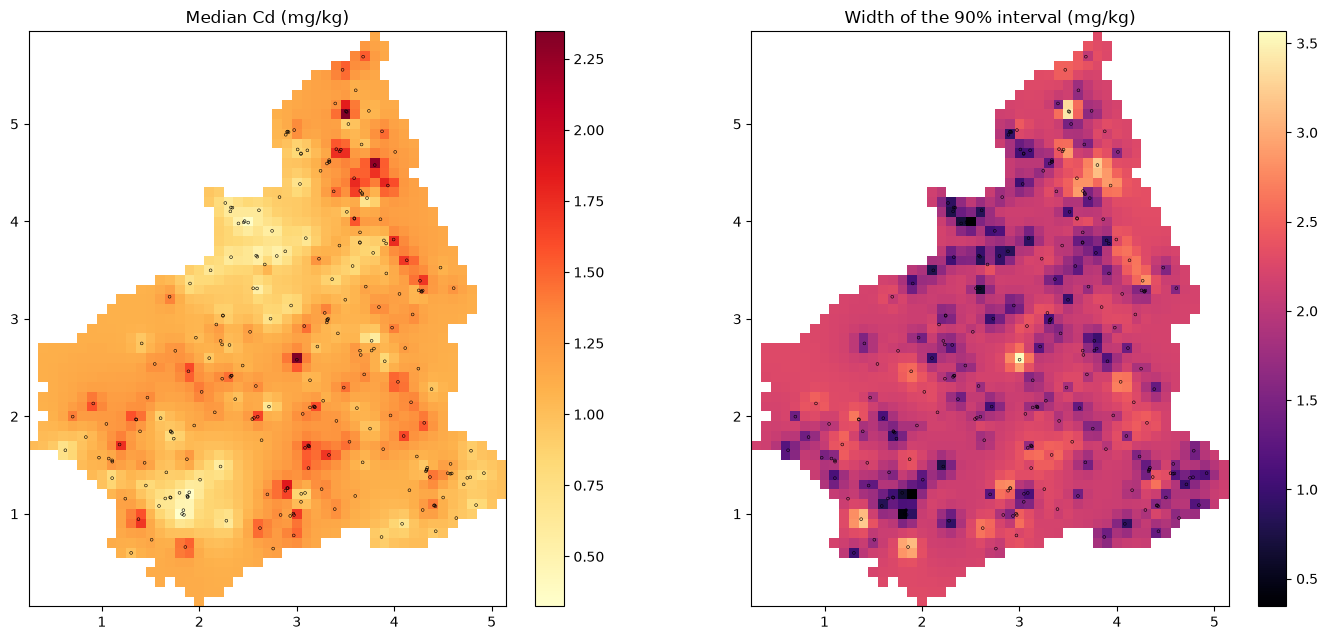

In [13]:
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
g = grid_df[["Xloc", "Yloc"]].to_numpy(float)
i50 = np.rint((g[:, 0] - g[:, 0].min()) / 0.05).astype(int)
j50 = np.rint((g[:, 1] - g[:, 1].min()) / 0.05).astype(int)
grid = g[(i50 % 2 == 0) & (j50 % 2 == 0)]
gi = np.rint((grid[:, 0] - grid[:, 0].min()) / 0.1).astype(int)
gj = np.rint((grid[:, 1] - grid[:, 1].min()) / 0.1).astype(int)
EXT = [grid[:, 0].min() - 0.05, grid[:, 0].max() + 0.05, grid[:, 1].min() - 0.05, grid[:, 1].max() + 0.05]
t0 = time.perf_counter()
gmap = bayesian_kriging(xy, z, grid, model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)
print(f"{len(grid)} nodes in {time.perf_counter() - t0:.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (v, title, cm) in zip(axes, [(np.exp(gmap.q50), "Median Cd (mg/kg)", "YlOrRd"),
                                     (np.exp(gmap.q95) - np.exp(gmap.q05), "Width of the 90% interval (mg/kg)", "magma")]):
    img = np.full((gj.max() + 1, gi.max() + 1), np.nan)
    img[gj, gi] = v
    im = ax.imshow(img, origin="lower", extent=EXT, cmap=cm, interpolation="nearest")
    ax.scatter(xy[:, 0], xy[:, 1], s=4, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In mg/kg, the interval width is larger where cadmium is high. A fixed width on the log scale becomes proportional to the level after back-transformation, as it should be for a skewed variable.

***
## Run Time

The cost grows with the number of data $n$ (Cholesky, $n^3$), the number of grid points $G$, and the number of prediction points $m$. Times for one call (mean, sd and three quantiles) with the default grids (30 × 5 = 150 grid points):

In [14]:
rows = []
rng = np.random.default_rng(0)
all_xy = jura[["Xloc", "Yloc"]].to_numpy(float)
all_z = np.log(jura["Cd"].to_numpy(float))
for n in [50, 100, 200, 359]:
    idx = rng.choice(len(all_z), n, replace=False)
    for m in [100, 1540]:
        pts = grid[:m]
        t0 = time.perf_counter()
        bayesian_kriging(all_xy[idx], all_z[idx], pts)
        rows.append({"n data": n, "m prediction points": m, "seconds": time.perf_counter() - t0})
timing = pd.DataFrame(rows).pivot(index="n data", columns="m prediction points", values="seconds")
timing.round(2)

m prediction points,100,1540
n data,,
50,0.52,6.95
100,0.54,7.31
200,0.85,7.43
359,0.87,17.27


* **The number of prediction points dominates.** 100 points take about 0.5-0.9 s; 1,540 points take 7-19 s.
* **The number of data matters less**, until $n$ grows: going from 50 to 200 data adds little, and 359 data double the time for the large grid.

Most of the time goes into the per-grid-point predictions and the quantile bisection. To save time on big grids:

* use a coarser `range_grid` or `nugget_grid`;
* request fewer quantiles;
* or call `predict` (mean and sd only) on the fitted model from `return_model=True`.

***
## Summary and Conclusions

In [15]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,matern with nu = 0.5 equals exponential,PASS,
1,quantiles ordered and median within the 90% in...,PASS,
2,signal and observation means agree,PASS,
3,"coverage within [0.80, 0.98] for every metal",PASS,range 0.84-0.94


- **`bayesian_kriging`** runs a full Bayesian kriging analysis in one call: a posterior over a grid of ranges and nugget ratios, with the trend and variance integrated out exactly. It returns the exact predictive mean, sd and quantiles as a table.
- **`correlation_function`** shows what the `range_` parameter means for each model: correlation drops below 0.05 at 0.81, 3 and 1.73 × `range_` for the spherical, exponential and Gaussian models.
- **Every option of `BayesianKriging` passes through**: model, grids, priors, trend and covariates. `return_model=True` gives the fitted model for exceedance probabilities and joint draws.
- **`signal=False` is essential for validation.** Signal intervals covered only 82% of held-out measurements; observation intervals covered 93.5%.
- **One-line comparisons** picked the exponential model for log-cadmium. A loop over seven metals took 6.6 s and showed hot-spot metals (Cu, Pb) to be the least predictable and slightly under-covered.
- **On the log scale, back-transform quantiles, not the mean.** The exponential of the log-scale mean is 12% below the observed average.

### Cheat sheet

```python
from geolattice.geostatistics import bayesian_kriging

# defaults: exponential model, constant mean, 30 ranges x 5 nugget ratios, flat / 1-over-sigma2 priors
t = bayesian_kriging(xy, z, xy_new)

# validation against measurements: include the nugget
t = bayesian_kriging(xy, z, xy_test, signal=False)

# chosen model, grids, priors, trend, covariates, extra quantiles
t = bayesian_kriging(xy, z, xy_new, model="spherical", trend=1,
                     range_grid=np.geomspace(0.1, 4, 25), nugget_grid=[0, 0.25, 0.5, 1],
                     range_prior="reciprocal", covariates=X, covariates_pred=X_new,
                     quantiles=(0.025, 0.5, 0.975))

# keep the fitted model for posterior, draws and exceedance probabilities
t, model = bayesian_kriging(xy, z, xy_new, return_model=True)
model.posterior_, model.predict_proba(xy_new, threshold), model.predictive_samples(xy_new, 1000, joint=True)
```

***
## References

| Reference | Used for |
|---|---|
| Handcock, M.S. & Stein, M.L. (1993). A Bayesian analysis of kriging. *Technometrics* 35, 403-410. | Bayesian kriging |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | Grid posterior (geoR `krige.bayes`) |
| Stein, M.L. (1999). *Interpolation of Spatial Data: Some Theory for Kriging*. Springer. | Matérn model |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura data |